# Analysis : What natural features of a route are key factors in determining its grade ?

## 1. Library imports 

In [4]:
import os
os.environ["PYTENSOR_FLAGS"] = "cxx=g++ -fexhaustive-register-search"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import re
import unicodedata
import bambi as bmb
import arviz as az
import h5netcdf

In [ ]:
import pytensor
print(pytensor.config.cxx)  

g++ -fexhaustive-register-search


## 2. Data imports

In [6]:
df = pd.read_csv("annotation_finale_ponderee.csv")
df

C:\Users\lunag\AppData\Local\Temp\ipykernel_31860\1127046363.py:1: DtypeWarning: Columns (31) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("annotation_finale_ponderee.csv")


,document_id,title,title_prefix,quality,activities,climbing_outdoor_type,global_rating,engagement_rating,risk_rating,equipment_rating,...,arête_ponderation,couloir_ponderation,trou_ponderation,réglette_ponderation,cannelure_ponderation,goutte_eau_ponderation,plat_ponderation,bac_ponderation,éperon_ponderation,crochet_ponderation
0,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1948176,Triangle des Coutchets - Soleil d'automne,Pic des Coutchets,medium,rock_climbing,multi,TD-,NaN,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1944609,Capricho,Aiguille de la Canalona,medium,rock_climbing,multi,D+,NaN,NaN,P2+,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42856,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42857,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42858,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
42859,53893,Voie Directe,Miroir d'Argentine,fine,rock_climbing,multi,D,II,NaN,P2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 3. Data manipulation

In [ ]:
grade_order = [
    "1a", "1b", "1b+", "1c+", 
    "2a", "2a+", "2b", "2b+", "2c", "2c+", 
    "3a", "3a+", "3b", "3b+", "3c", "3c+", 
    "4a", "4a+", "4b", "4b+", "4c", "4c+", 
    "5a", "5a+", "5b", "5b+", "5c", "5c+", 
    "6a", "6a+", "6b", "6b+", "6c", "6c+",
    "7a", "7a+", "7b", "7b+", "7c", "7c+", 
    "8a", "8a+", "8b", "8b+", "8c", "8c+",
    "9a+"
]

In [ ]:
# Grade order

df["difficulty"] = pd.Categorical(
    df["difficulty"],
    categories=grade_order,
    ordered=True
)

In [ ]:
# Frequents : kept as numeric count, capped at 3
elements_frequents = [
    "dalle", "fissure", "dièdre", "traversée", "surplomb",
    "dévers", "cheminée", "vire", "arête", "pilier", "terrasse", "éperon",
]

# Intermediate : binarized as presence/absence
elements_intermediaires = [
    "écailles", "trou", "couloir", "cannelure", "réglette",
    "goutte_eau", "crochet", "bac", "plat", "petite_prise", "faille",
]

# Very rare elements, excluded from the model
elements_rares = [
    "pince", "mono_doigt", "bi_doigt", "contrefort", "corniche",
    "épaule", "inversee", "fissure-dièdre",
]

# --- Construction of the analysis dataset (df remains intact) ---
df_model = df.copy()

# Frequents : kept as numeric count, capped at 3
for e in elements_frequents:
    df_model[f"nb_{e}"] = pd.to_numeric(df_model[f"nb_{e}"]).clip(upper=3)

# 2. Intermediate : binarized as presence/absence
for e in elements_intermediaires:
    df_model[f"pres_{e}"] = (pd.to_numeric(df_model[f"nb_{e}"]) > 0).astype(int)

# 3. Selection of final columns : model variables + identifiers
colonnes_modele = (
    [f"nb_{e}"  for e in elements_frequents] +
    [f"pres_{e}" for e in elements_intermediaires]
)
df_model = df_model[colonnes_modele + ["difficulty", "document_id", 'log_nb_terms_description']].copy()

# 4. Remove incomplete rows (if there are any residual NaNs)
df_model = df_model.dropna(subset=colonnes_modele + ["difficulty"]).reset_index(drop=True)

## 4. Analysis

In [ ]:
# ============================================================
# PARAMETERS TO ADJUST FOR THE MODEL
# ============================================================
COL_COTATION = "difficulty"                 
COL_VOIE = "document_id"
PREDICTEURS = ['nb_dalle',
 'nb_fissure',
 'nb_dièdre',
 'nb_traversée',
 'nb_surplomb',
 'nb_dévers',
 'nb_cheminée',
 'nb_vire',
 'nb_arête',
 'nb_pilier',
 'nb_terrasse',
 'nb_éperon',
 'pres_écailles',
 'pres_trou',
 'pres_couloir',
 'pres_cannelure',
 'pres_réglette',
 'pres_goutte_eau',
 'pres_crochet',
 'pres_bac',
 'pres_plat',
 'pres_petite_prise',
 'pres_faille',
 'log_nb_terms_description']   

# Grade classes: we bound the extremes (rare) -> here 15 classes
COTATION_MIN = "4c+"                        # everything below this threshold is grouped into the first class

COTATION_MAX = "7a+"                        # everything above this threshold is grouped into the last class

SEPARER_ENTRE_INTRA = True                  # True: Separate within-route and between-route effects
N_VOIES_TEST = None                         # ex. 300 for a quick test ; None = tout

DOSSIER = "resultats"
PREFIXE = os.path.join(DOSSIER, "ordinaleA_Total_bambi")

In [ ]:
# ============================================================
# TOOLS
# ============================================================
def nettoyer_nom(nom):
    """Column name without accents or special characters (required for Bambi formulas)."""
    s = unicodedata.normalize("NFKD", nom).encode("ascii", "ignore").decode()
    return re.sub(r"\W+", "_", s).strip("_")


ORDRE = [f"{n}{l}{p}" for n in range(1, 10) for l in "abc" for p in ["", "+"]]
RANG = {g: i for i, g in enumerate(ORDRE)}


def cotation_vers_classe(serie):
    """Grade -> increasing integer (1 = easiest), with extremes grouped."""
    rang = serie.astype("string").str.strip().str.lower().map(RANG).astype(float)
    bas, haut = RANG[COTATION_MIN], RANG[COTATION_MAX]
    return rang.clip(lower=bas, upper=haut) - bas + 1

In [12]:
# ============================================================
# 1. DATA PREPARATION
# ============================================================

data = pd.DataFrame({
    "classe_cotation": cotation_vers_classe(df_model[COL_COTATION]),
    COL_VOIE: df_model[COL_VOIE],
})
noms_propres = {p: nettoyer_nom(p) for p in PREDICTEURS}
for p, propre in noms_propres.items():
    data[propre] = pd.to_numeric(df_model[p], errors="coerce")
predicteurs = list(noms_propres.values())

data = data.dropna(subset=["classe_cotation"] + predicteurs).copy()
data["classe_cotation"] = data["classe_cotation"].astype(int)
print(f"{len(data)} rows, {data[COL_VOIE].nunique()} routes, "
      f"{data['classe_cotation'].nunique()} grade classes")

if N_VOIES_TEST:
    voies = data[COL_VOIE].drop_duplicates().sample(N_VOIES_TEST, random_state=0)
    data = data[data[COL_VOIE].isin(voies)].copy()
    print(f"Quick test: {data[COL_VOIE].nunique()} routes, {len(data)} lignes")

if SEPARER_ENTRE_INTRA:
    nouvelles = []
    for p in predicteurs:
        moyenne = data.groupby(COL_VOIE)[p].transform("mean")
        data[p + "_moy_voie"] = moyenne          # between-route effect
        data[p + "_ecart"] = data[p] - moyenne   # within-route effect
        nouvelles += [p + "_ecart", p + "_moy_voie"]
    predicteurs = nouvelles

SEUIL_FUSION = 20 if N_VOIES_TEST else 400
effectifs = data["classe_cotation"].value_counts().sort_index()
mapping = {}
for c in effectifs.index:
    if effectifs[c] < SEUIL_FUSION and (c - 1) in effectifs.index:
        mapping[c] = c - 1      # merge into the lower grade class
    else:
        mapping[c] = c
data["classe_cotation"] = data["classe_cotation"].map(mapping)
print("Grade-class counts after merging:")
print(data["classe_cotation"].value_counts().sort_index())

os.makedirs(DOSSIER, exist_ok=True)
data.to_csv(os.path.join(DOSSIER, "donnees_prepareesA.csv"), index=False)

42861 rows, 9299 routes, 15 grade classes
Grade-class counts after merging:
classe_cotation
1     5747
2     2358
4     4245
5      521
6     5996
7     1064
8     6303
9     4084
10    4144
11    2424
12    2278
13    1054
14    1121
15    1522
Name: count, dtype: int64


In [13]:
exclues = {"classe_cotation", COL_VOIE}
predicteurs_modele = nouvelles    # only the _ecart/_moy_voie terms (48), not the raw predictors

# 1) Data: standardization + winsorization (as in the R script)
df_bayes = data.copy()
for p in predicteurs_modele:
    x = df_bayes[p].astype(float)
    z = (x - x.mean()) / x.std()
    df_bayes[p] = z.clip(-10, 10)          # winsorization at ±10

# 2) Response = ORDERED category (required for the cumulative family)
categories = sorted(df_bayes["classe_cotation"].unique())
df_bayes["classe_cotation"] = pd.Categorical(df_bayes["classe_cotation"],
                                             categories=categories, ordered=True)
# 3) Route must be a factor, not a number
df_bayes[COL_VOIE] = df_bayes[COL_VOIE].astype("category")

# 4) Weakly informative priors
priors = {p: bmb.Prior("Normal", mu=0, sigma=2) for p in predicteurs_modele}
priors["group_specific"] = bmb.Prior(
    "Normal", mu=0, sigma=bmb.Prior("HalfNormal", sigma=2.5)
)
formule = ("classe_cotation ~ " + " + ".join(predicteurs_modele)
           + f" + (1|{COL_VOIE})")
print(formule)

model = bmb.Model(formule, df_bayes, family="cumulative", priors=priors)
print(model)

# 5) Full run
idata = model.fit(
    draws=1500,
    tune=1000,
    chains=4,
    cores=4,
    inference_method="nutpie",
    random_seed=42,
    progressbar=False,
)

idata.to_netcdf("idata_A.nc")   

# 6) DIAGNOSTICS — validation criteria
resume = az.summary(idata, ci_prob=0.95, round_to=3)
print(resume)
# Check: r_hat ≈ 1.00 throughout (max < 1.01) and ess_bulk > 400
print("Maximum R-hat:", resume["r_hat"].max())

# 7) Export results to CSV
post = az.summary(idata, var_names=predicteurs_modele, ci_prob=0.95)
res = pd.DataFrame({
    "variable":   post.index,
    "coef":       post["mean"],
    "erreur_std": post["sd"],
    "ic_bas":     post["eti95_lb"],
    "ic_haut":    post["eti95_ub"],
})
res["odds_ratio"] = np.exp(res["coef"])
res.to_csv(f"{PREFIXE}_coefficients.csv", index=False)

sigma_voie = float(az.summary(idata, var_names=[f"1|{COL_VOIE}_sigma"])["mean"].iloc[0])

pd.DataFrame({"n_obs": [len(df_bayes)],
              "n_voies": [df_bayes[COL_VOIE].nunique()],
              "n_classes": [df_bayes["classe_cotation"].nunique()],
              "sd_alea": [sigma_voie],
              "variance_alea": [sigma_voie**2]}
             ).to_csv(f"{PREFIXE}_ajustement.csv", index=False)
print("Results written to:", PREFIXE, "_*.csv")

classe_cotation ~ nb_dalle_ecart + nb_dalle_moy_voie + nb_fissure_ecart + nb_fissure_moy_voie + nb_diedre_ecart + nb_diedre_moy_voie + nb_traversee_ecart + nb_traversee_moy_voie + nb_surplomb_ecart + nb_surplomb_moy_voie + nb_devers_ecart + nb_devers_moy_voie + nb_cheminee_ecart + nb_cheminee_moy_voie + nb_vire_ecart + nb_vire_moy_voie + nb_arete_ecart + nb_arete_moy_voie + nb_pilier_ecart + nb_pilier_moy_voie + nb_terrasse_ecart + nb_terrasse_moy_voie + nb_eperon_ecart + nb_eperon_moy_voie + pres_ecailles_ecart + pres_ecailles_moy_voie + pres_trou_ecart + pres_trou_moy_voie + pres_couloir_ecart + pres_couloir_moy_voie + pres_cannelure_ecart + pres_cannelure_moy_voie + pres_reglette_ecart + pres_reglette_moy_voie + pres_goutte_eau_ecart + pres_goutte_eau_moy_voie + pres_crochet_ecart + pres_crochet_moy_voie + pres_bac_ecart + pres_bac_moy_voie + pres_plat_ecart + pres_plat_moy_voie + pres_petite_prise_ecart + pres_petite_prise_moy_voie + pres_faille_ecart + pres_faille_moy_voie + log_n

c:\Python313\Lib\site-packages\bambi\formula.py:112: UserWarning: The intercept is omitted in ordinal families
  warnings.warn("The intercept is omitted in ordinal families")


       Formula: classe_cotation ~ nb_dalle_ecart + nb_dalle_moy_voie + nb_fissure_ecart + nb_fissure_moy_voie + nb_diedre_ecart + nb_diedre_moy_voie + nb_traversee_ecart + nb_traversee_moy_voie + nb_surplomb_ecart + nb_surplomb_moy_voie + nb_devers_ecart + nb_devers_moy_voie + nb_cheminee_ecart + nb_cheminee_moy_voie + nb_vire_ecart + nb_vire_moy_voie + nb_arete_ecart + nb_arete_moy_voie + nb_pilier_ecart + nb_pilier_moy_voie + nb_terrasse_ecart + nb_terrasse_moy_voie + nb_eperon_ecart + nb_eperon_moy_voie + pres_ecailles_ecart + pres_ecailles_moy_voie + pres_trou_ecart + pres_trou_moy_voie + pres_couloir_ecart + pres_couloir_moy_voie + pres_cannelure_ecart + pres_cannelure_moy_voie + pres_reglette_ecart + pres_reglette_moy_voie + pres_goutte_eau_ecart + pres_goutte_eau_moy_voie + pres_crochet_ecart + pres_crochet_moy_voie + pres_bac_ecart + pres_bac_moy_voie + pres_plat_ecart + pres_plat_moy_voie + pres_petite_prise_ecart + pres_petite_prise_moy_voie + pres_faille_ecart + pres_faille_

NUTS[nutpie]: [threshold, nb_dalle_ecart, nb_dalle_moy_voie, nb_fissure_ecart, nb_fissure_moy_voie, nb_diedre_ecart, nb_diedre_moy_voie, nb_traversee_ecart, nb_traversee_moy_voie, nb_surplomb_ecart, nb_surplomb_moy_voie, nb_devers_ecart, nb_devers_moy_voie, nb_cheminee_ecart, nb_cheminee_moy_voie, nb_vire_ecart, nb_vire_moy_voie, nb_arete_ecart, nb_arete_moy_voie, nb_pilier_ecart, nb_pilier_moy_voie, nb_terrasse_ecart, nb_terrasse_moy_voie, nb_eperon_ecart, nb_eperon_moy_voie, pres_ecailles_ecart, pres_ecailles_moy_voie, pres_trou_ecart, pres_trou_moy_voie, pres_couloir_ecart, pres_couloir_moy_voie, pres_cannelure_ecart, pres_cannelure_moy_voie, pres_reglette_ecart, pres_reglette_moy_voie, pres_goutte_eau_ecart, pres_goutte_eau_moy_voie, pres_crochet_ecart, pres_crochet_moy_voie, pres_bac_ecart, pres_bac_moy_voie, pres_plat_ecart, pres_plat_moy_voie, pres_petite_prise_ecart, pres_petite_prise_moy_voie, pres_faille_ecart, pres_faille_moy_voie, log_nb_terms_description_ecart, log_nb_term

                         mean     sd  eti95_lb  eti95_ub   ess_bulk  ess_tail  \
nb_dalle_ecart          0.071  0.008     0.054     0.088  13789.522  4351.030   
nb_dalle_moy_voie      -0.266  0.023    -0.312    -0.220   1522.072  2286.563   
nb_fissure_ecart        0.182  0.009     0.165     0.199  12015.057  4659.519   
nb_fissure_moy_voie     0.214  0.023     0.167     0.260   1628.166  2405.878   
nb_diedre_ecart         0.046  0.009     0.030     0.063  12514.500  4058.117   
...                       ...    ...       ...       ...        ...       ...   
1|document_id[1947930] -1.281  1.173    -3.661     1.027  12789.351  4066.030   
1|document_id[1948149] -0.601  1.288    -3.068     1.903  13984.823  4249.421   
1|document_id[1948176] -0.207  0.728    -1.629     1.227  10763.543  4463.616   
1|document_id[1948501]  0.063  0.788    -1.498     1.547  11715.324  4190.676   
1|document_id[1948840] -1.811  0.747    -3.322    -0.384  10802.911  3806.895   

                        r_h

 n_obs  n_voies  n_classes  sd_alea  variance_alea
 42861     9299         14 2.121493       4.500733
                         variable   coef  erreur_std  ic_bas  ic_haut  odds_ratio
                   nb_dalle_ecart  0.071       0.008   0.054    0.088       1.074
                nb_dalle_moy_voie -0.266       0.023  -0.312   -0.220       0.766
                 nb_fissure_ecart  0.182       0.009   0.165    0.199       1.199
              nb_fissure_moy_voie  0.214       0.023   0.167    0.260       1.238
                  nb_diedre_ecart  0.046       0.009   0.030    0.063       1.047
               nb_diedre_moy_voie -0.011       0.024  -0.057    0.038       0.989
               nb_traversee_ecart  0.009       0.009  -0.009    0.027       1.009
            nb_traversee_moy_voie  0.107       0.024   0.062    0.155       1.113
                nb_surplomb_ecart  0.182       0.009   0.165    0.199       1.200
             nb_surplomb_moy_voie  0.295       0.023   0.249    0.340       1.

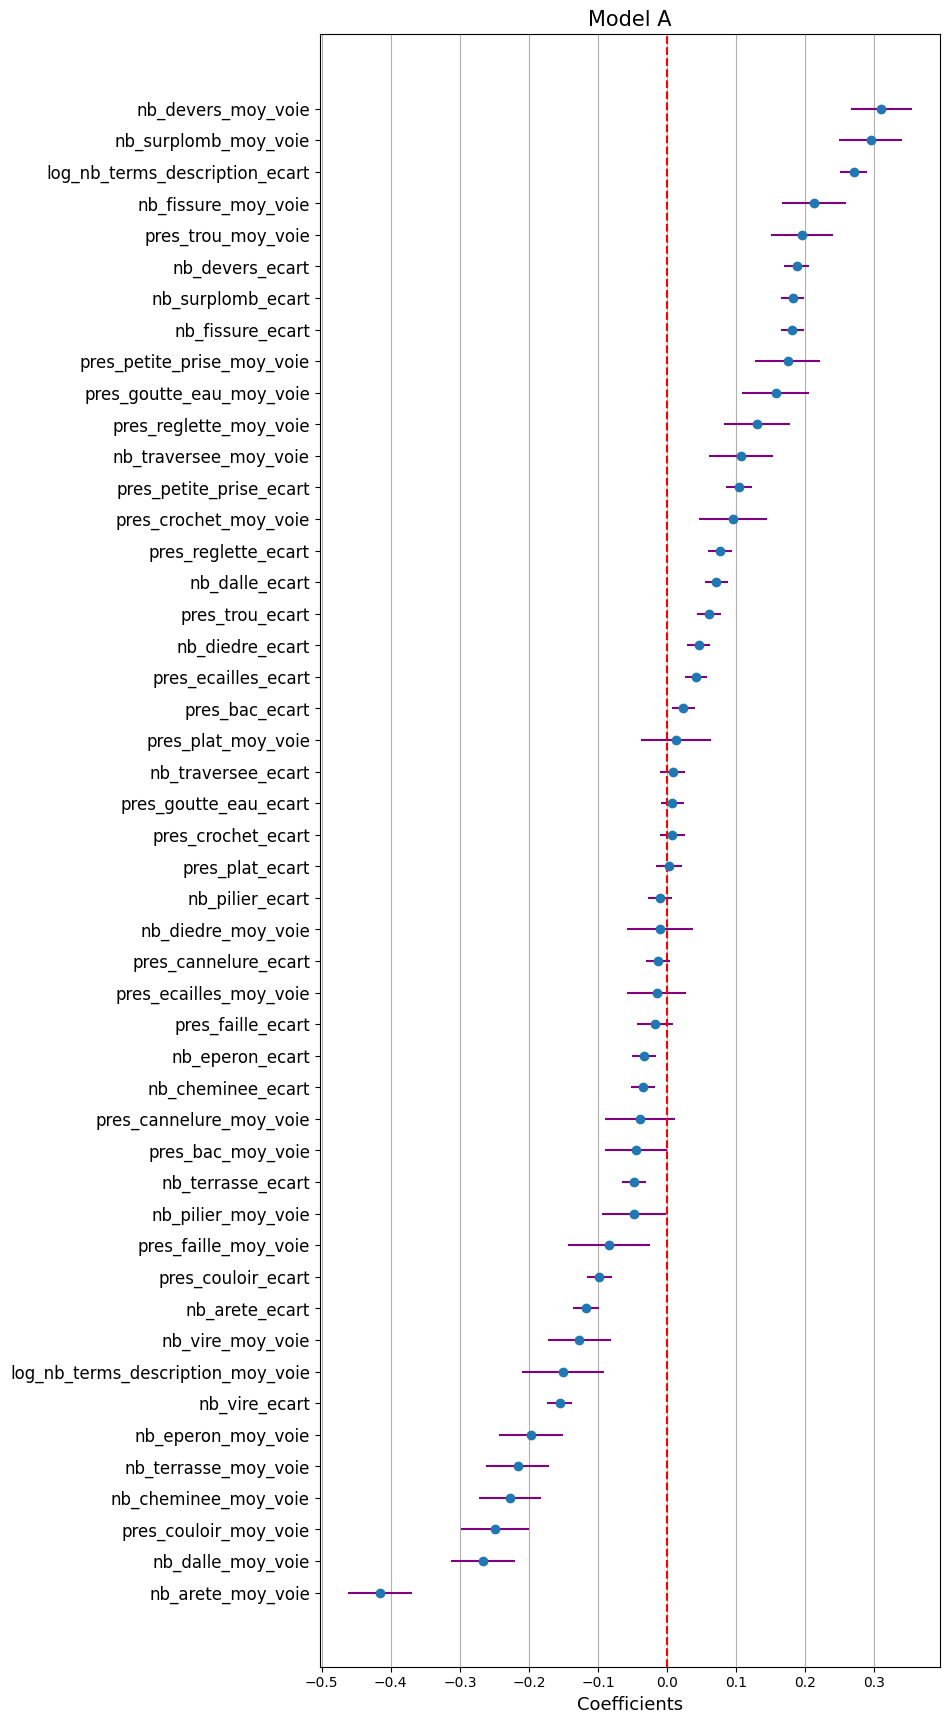

In [16]:
# ============================================================
# 3. RESULTS
# ============================================================
coefs = pd.read_csv(PREFIXE + "_coefficients.csv")
ajust = pd.read_csv(PREFIXE + "_ajustement.csv")
print(ajust.to_string(index=False))
print(coefs.round(3).to_string(index=False))

# Forest plot (coefficients; positive values indicate a higher grade)
coefs = coefs.sort_values("coef").reset_index(drop=True)
y_pos = range(1, len(coefs) + 1)
ci = (coefs["ic_haut"] - coefs["ic_bas"]) / 2

plt.figure(figsize=(8, 0.4 * len(coefs) + 2))
plt.errorbar(coefs["coef"], y_pos, xerr=ci, fmt="o", ecolor="purple")
plt.yticks(y_pos, coefs["variable"], fontsize=12)
plt.axvline(x=0, linestyle="--", color="red")
plt.xlabel("Coefficients", fontsize=13)
plt.title("Model A", fontsize=15)
plt.grid(axis="x")